In [1]:
import json
import time
import urllib.error
import urllib.parse
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

model = CatBoostClassifier()
model.load_model("models/icu_death.cbm")

df = pd.read_csv("data/training_v2.csv")
dictionary = pd.read_csv("data/WiDS Datathon 2020 Dictionary.csv")

print("loaded trees:", model.tree_count_)
print("rows:", len(df))


loaded trees: 322
rows: 91713


In [2]:
drop_columns = [
    "encounter_id",
    "patient_id",
    "hospital_id",
    "icu_id",
    "hospital_death",
    "apache_4a_hospital_death_prob",
    "apache_4a_icu_death_prob",
]

cat_columns = [
    "ethnicity",
    "gender",
    "hospital_admit_source",
    "icu_admit_source",
    "icu_stay_type",
    "icu_type",
    "apache_3j_bodysystem",
    "apache_2_bodysystem",
    "apache_2_diagnosis",
    "apache_3j_diagnosis",
]

y = df["hospital_death"].astype(int)
X = df.drop(columns=drop_columns)

for col in cat_columns:
    X[col] = X[col].fillna("missing")
    X[col] = X[col].astype(str)

print("features:", X.shape[1])


features: 179


In [3]:
X_rest, X_test, y_rest, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

risk = model.predict_proba(X_test)[:, 1]
y_true = y_test.to_numpy()

print("test AUC:", round(roc_auc_score(y_true, risk), 3))

died_rows = np.where(y_true == 1)[0]
typical_death_risk = np.median(risk[died_rows])
row = died_rows[np.argmin(np.abs(risk[died_rows] - typical_death_risk))]

patient = X_test.iloc[[row]]
patient_risk = float(risk[row])

print("died:", int(y_true[row]))
print("model risk:", round(patient_risk, 3))
print("typical death risk:", round(float(typical_death_risk), 3))


test AUC: 0.908
died: 1
model risk: 0.32
typical death risk: 0.32


In [4]:
shap_row = model.get_feature_importance(
    Pool(patient, cat_features=cat_columns),
    type="ShapValues",
)[0]

start_score = shap_row[-1]
pushes = shap_row[:-1]

explain = pd.DataFrame({
    "feature": list(patient.columns),
    "value": patient.iloc[0].to_numpy(),
    "push": pushes,
})
explain["size"] = explain["push"].abs()
explain = explain.sort_values("size", ascending=False)

print("class 1, died")
print("starting score:", round(float(start_score), 3))
print("sum of pushes:", round(float(pushes.sum()), 3))
print()
print(explain.head(10).drop(columns="size").to_string(index=False))


class 1, died
starting score: -3.446
sum of pushes: 2.694

           feature     value     push
               age      85.0 0.522936
  d1_heartrate_max     177.0 0.424106
      d1_sysbp_min      70.0 0.239306
  gcs_motor_apache       4.0 0.230188
  pre_icu_los_days  2.195833 0.134528
   gcs_eyes_apache       2.0 0.125244
  icu_admit_source     Floor 0.120320
       d1_spo2_min      87.0 0.119688
 gcs_verbal_apache       2.0 0.113646
apache_2_diagnosis     110.0 0.111355


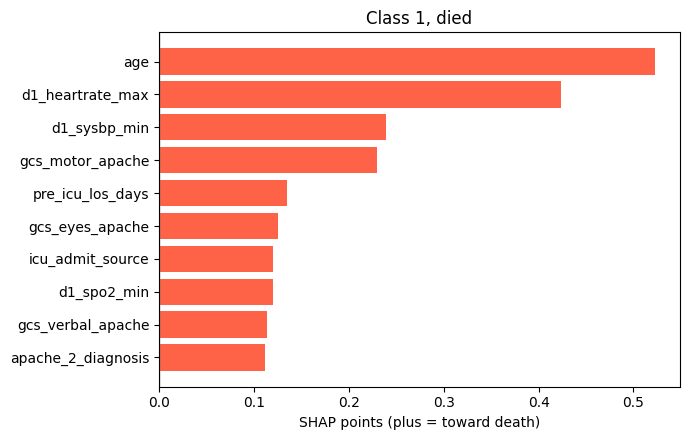

In [5]:
top = explain.head(10).iloc[::-1]
colors = ["tomato" if push > 0 else "steelblue" for push in top["push"]]

plt.figure(figsize=(7, 4.5))
plt.barh(top["feature"], top["push"], color=colors)
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("SHAP points (plus = toward death)")
plt.title("Class 1, died")
plt.tight_layout()
plt.show()


In [6]:
start_score_0 = -start_score
pushes_0 = -pushes

explain_0 = pd.DataFrame({
    "feature": list(patient.columns),
    "value": patient.iloc[0].to_numpy(),
    "push": pushes_0,
})
explain_0["size"] = explain_0["push"].abs()
explain_0 = explain_0.sort_values("size", ascending=False)

print("class 0, survived")
print("model risk:", round(1 - patient_risk, 3))
print("starting score:", round(float(start_score_0), 3))
print("sum of pushes:", round(float(pushes_0.sum()), 3))
print()
print(explain_0.head(10).drop(columns="size").to_string(index=False))


class 0, survived
model risk: 0.68
starting score: 3.446
sum of pushes: -2.694

           feature     value      push
               age      85.0 -0.522936
  d1_heartrate_max     177.0 -0.424106
      d1_sysbp_min      70.0 -0.239306
  gcs_motor_apache       4.0 -0.230188
  pre_icu_los_days  2.195833 -0.134528
   gcs_eyes_apache       2.0 -0.125244
  icu_admit_source     Floor -0.120320
       d1_spo2_min      87.0 -0.119688
 gcs_verbal_apache       2.0 -0.113646
apache_2_diagnosis     110.0 -0.111355


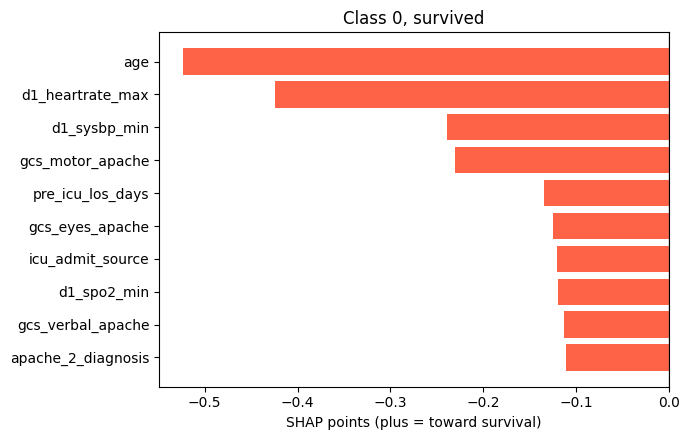

In [7]:
top = explain_0.head(10).iloc[::-1]
colors = ["steelblue" if push > 0 else "tomato" for push in top["push"]]

plt.figure(figsize=(7, 4.5))
plt.barh(top["feature"], top["push"], color=colors)
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("SHAP points (plus = toward survival)")
plt.title("Class 0, survived")
plt.tight_layout()
plt.show()


In [2]:
def column_query(feature):
    drop = {"d1", "h1", "min", "max", "mean", "median", "apache"}
    words = []
    for word in str(feature).lower().split("_"):
        if word in drop or word.isdigit():
            continue
        words.append(word)
    return " ".join(words)


def description_query(description):
    if pd.isna(description):
        return ""
    text = str(description).lower()
    for prefix in ("the patient's ", "the "):
        if text.startswith(prefix):
            text = text[len(prefix):]
    text = text.split(" during ")[0].split(" measured ")[0].split(" which ")[0]
    return text.strip(" .")


def ols_search(query, n=3):
    if not query:
        return []
    params = urllib.parse.urlencode({"q": query, "rows": n, "lang": "en"})
    url = "https://www.ebi.ac.uk/ols4/api/search?" + params
    request = urllib.request.Request(
        url,
        headers={"Accept": "application/json", "User-Agent": "fraunhofer-xai"},
    )
    for attempt in range(4):
        try:
            with urllib.request.urlopen(request, timeout=40) as response:
                payload = json.load(response)
            break
        except (urllib.error.HTTPError, TimeoutError) as exc:
            if attempt == 3:
                raise
            if isinstance(exc, urllib.error.HTTPError) and exc.code != 429:
                raise
            time.sleep(1.5 * (attempt + 1))
    time.sleep(0.4)
    return payload["response"]["docs"]



def first_hit(docs):
    if not docs:
        return "no hit"
    doc = docs[0]
    code = doc.get("obo_id") or doc.get("short_form")
    return f"{doc.get('label')} | {code} | {doc.get('ontology_name')}"


In [9]:
descriptions = (
    dictionary.drop_duplicates("Variable Name")
    .set_index("Variable Name")["Description"]
)

top_features = explain.head(10)
print("Concept lookup in OLS. Two ways to name the same column.")
print()

for feature_row in top_features.itertuples(index=False):
    from_column = column_query(feature_row.feature)
    from_description = description_query(descriptions.get(feature_row.feature, ""))
    print(
        feature_row.feature,
        "| value:", feature_row.value,
        "| push:", round(float(feature_row.push), 3),
    )
    print("  column query:", from_column)
    print("   ", first_hit(ols_search(from_column)))
    print("  description query:", from_description)
    print("   ", first_hit(ols_search(from_description)))
    print()


Concept lookup in OLS. Two ways to name the same column.

age | value: 85.0 | push: 0.523
  column query: age


    Age | NCIT:C25150 | ncit
  description query: age of the patient on unit admission


    no hit

d1_heartrate_max | value: 177.0 | push: 0.424
  column query: heartrate


    Tachycardia | HP:0001649 | hp
  description query: highest heart rate


    no hit

d1_sysbp_min | value: 70.0 | push: 0.239
  column query: sysbp


...

    no hit

gcs_verbal_apache | value: 2.0 | push: 0.114
  column query: gcs verbal


    Glasgow Coma Scale-NINDS Version 1.0 - Verbal Response | NCIT:C124726 | ncit
  description query: verbal component of the glasgow coma scale measured


    no hit

apache_2_diagnosis | value: 110.0 | push: 0.111
  column query: diagnosis


    Diagnosis | mesh:D003933 | mesh
  description query: apache ii diagnosis for the icu admission


    no hit

